# Task 3: Methods of Decision Analysis Final Project

### Authors: Javier Gonzalo & Mauricio Valdez

## Brief Introduction

After developing the Task 2 notebook, Task 3 puts us in a similar situation in which we have to create a network (suggested to us to have a structure of [784,N,10] layers) that analyzes an even bigger dataset (60,000 examples) to recognize digits from 0-9. The most apparent change is the number of input variables that may seem excessively many to start with but begin to make sense as the notebook progresses. Throughout this notebook we create batches, explore the concepts of epochs and relu and end up with a neural model that was worth doing.

### Importing libraries

In [16]:
import gzip #to open the file type
import pickle #to load the images into different tipes of data with specific encoding.
import numpy as np
import matplotlib.pyplot as plt 
import random
import pandas as pd

ModuleNotFoundError: No module named 'numpy'

### Loading data

As annotated in the importation of the libraries, to load the MNIST dataset, we must use 'gzip.open' to read the compressed file in the format '.gz' which is also understood as '.gzip. On the other hand, we also need pickle (a python module) to retrieve the MNIST data that was once stored as a python object and now it's recuperated as it was one stored. Another sign of this is that it was encoded in 'latin1' typical in Python2, not Python3.

In [ ]:
f = gzip.open('../Data/mnist.pkl.gz', 'rb')
training_data, validation_data, test_data = pickle.load(f, encoding="latin1")
f.close()   

FileNotFoundError: [Errno 2] No such file or directory: '../Data/mnist.pkl.gz'

## Same functions as Task 2

These first 5 functions are the same as the ones used in Task 2, all except the vectorized results since insted of being a 2-dimensional unit vector, it's now a 10-dimensional unit vector where the 1 is still placed in the jth position but the list is now 10 digits long to match the 10 numbers that can appear as an output of the network.

In [141]:
def vectorized_result(j):
    """Return a 10-dimensional unit vector with a 1.0 in the jth
    position and zeroes elsewhere.  This is used to convert a digit
    (0...9) into a corresponding desired output from the neural
    network."""
    e = np.zeros((10, 1))
    e[j] = 1.0
    return e
def sigmoid_prime(z):
    """Derivative of the sigmoid function."""
    return sigmoid(z)*(1-sigmoid(z))
def sigmoid(t):
    return 1/(1+np.exp(-t))
def evaluate(y_preds, y_target):
    # calculate the number of correct guesses in y_preds compared to the 
    # targets in y_target.
    num = sum([np.argmax(a) == np.argmax(b) for a,b in zip(y_preds, y_target)])
    return (num) 
def forward_pass(Weight, bias, x):
    for w, b in zip(Weight, bias):
        x = sigmoid(w @ x + b)
    return (x)

Having justified this, it's an excellent moment to answer to the first two questions of this task.

## *Task 3a.  Why are 784 layers appropriate for the input layer? (2p)*

Taking into account how in the last notebook we mentioned how there were the same amount of features than input variables, we clearly suspect that there are 784 total pixels (both black and white) which would make sense being an exact square number (of 28) if the picture is square but also to assign one pixel to one input variable. 

## *Task 3b. Why are 10 layers appropriate for the output layer? Are there other options? (3p)*

Once again, we are using the same number of nodes as the number of different outputs there is. In this case, we use 10 layers since we have 10 posible numbers that can come up (0-9). Consequently, due to the fact that we have 10 different possible outputs in the form of visual pictures (end up with the pixels being numbers), there is no binary choosing and reducing the number of output layers would make us lose information in a dataset where the output layers don't have really anything in common (we make sense of the combination of black pixels but the shape of digits don't have anything to do with one and another).

## Discovery 1: Attempting GPU Training with PyTorch

When deciding what the best approach to task 3 could be, we recognized and came to the conclusion that matrix calculations run much faster on GPU than CPU. On the one hand, the CPU is designed to do complex, sequential tasks quickly in its little amount but powerful number of cores (núcleos). On the other hand, the GPU has thousands of even smaller but simpler cores that work at the same time on large data blocks. In this case, matrix multiplications and calculations look more like repetitive, simultaneos operations instead of powerful sequential ones, meaning they would run faster on GPU than CPU. [source link: datacamp](https://www.datacamp.com/es/blog/cpu-vs-gpu)

Using Javier's Mac, we tried to take advantage of its shared memory architecture to attempt GPU training and even found recommended libraries for GPU-accelerated training on Pytorch but since the library used tensors and the existing codebase used Numpy arrays, the migration was too complex to justify and worth doing so we discarded this option [source for tensor information](https://cienciadedatos.net/documentos/pydl01-introduccion-pytorch)

## Discovery 2: The Rectified Linear Unit and the Leaky Linear Unit

$$
\text{ReLU}(t) =
\begin{cases}
t & \text{si } t > 0 \\
0 & \text{si } t \leq 0
\end{cases}
$$

#used ai to generate this form of text

While reading the Pytorch documentation to attempt the GPU training, we found a tutorial on image classification similar in approach to the task we had to complete that, for example, was used to classify t-shirt images. In this tutorial, we identified the use of a new activation function: the Rectified Linear Unit function. The function is simple to understand, if the input is bigger than 0 it let's it pass. Nevertheless, if the input value is 0 or lower, it gets rounded to 0, effectively "turning off" nodes in the network and benefiting the process by several ways (not exactly 0 but close enough for an initial explaination).

In addition, we were lucky to find that this aligned with Jonas' recommendations to improve the backpropagation code mathematically. Even though we started by using the standard formula to ReLU, we found ourselves with too many nodes being deactivated which therefore caused errors. Instead, we switched to Leaky ReLU which, in short, scales the small negative values by multiplying the t by 0.01 so that the values are not zeros and aren't totally inhibited.

Some of the benefits of this discovery have been to be computationally cheaper to differentiate compared to the previous activation function, fit better for multi-class, non-binary outputs (like these 10 output layers) and treat the "vanishing gradient" issue that appears in the sigmoid function when the values are too big or too small since the sigmoid curve ends up being really flat (close to 0) that makes the signals propagate slower and have a slower learning time (related to the first benefit).

Seeing that we could optimize the function, increasing the number of training epochs became feasible (related to task 2).

### Importing new functions and Pytorch reference

In [142]:
def relu(t, alpha = 0.01): #Leaky in reality 
    return np.where(t>0, t,alpha*t)

def relu_prime(z, alpha = 0.01):
    return np.where(z > 0, 1, alpha)

def forward_pass(Weight, bias, x):
    for w, b in zip(Weight, bias):
        x = relu(w @ x + b)
    return (x)


In [143]:
training_results = [vectorized_result(y) for y in training_data[1]]
training_inputs = [np.reshape(x, (784, 1)) for x in training_data[0]]
print(len(training_inputs), type(training_results), type(training_results))

50000 <class 'list'> <class 'list'>


In [ ]:
#sample_idx = np.random.choice(len(training_inputs), size=100, replace=False)

#training_inputs_sample  = [training_inputs[i] for i in sample_idx]
#training_results_sample = [training_results[i] for i in sample_idx]
#print(len(training_inputs_sample), type(training_results_sample), type(training_results_sample))

100 <class 'list'> <class 'list'>


https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html

In [145]:
#import os
import torch
#from torch import nn
#from torch.utils.data import DataLoader
#from torchvision import datasets, transforms

In [146]:
def backpropagation(bias, Weight, num_layers, x, y):
    nabla_b = [np.zeros(len(b)) for b in bias]
    nabla_w = [np.zeros_like(w) for w in Weight]
    # feedforward
    act = x
    act_list = [x] # store all activations layer-by-layer
    zs = [] # list to store all the z vectors, layer by layer
    for w, b in zip(Weight, bias):
        z = (w @ act + b)
        zs.append(z)
        act = relu(z)
        act_list.append(act)
    # backward pass:
    delta = relu_prime(zs[-1]) * (act_list[-1] - y)
    nabla_b[-1] = delta
    nabla_w[-1] = delta @ act_list[-2].T
    for l in range(2, num_layers):
        z = zs[-l]
        sp = relu_prime(z)
        delta = np.dot(Weight[-l+1].transpose(), delta) * sp
        nabla_b[-l] = delta
        nabla_w[-l] = delta @ act_list[-l-1].T
    return (nabla_b, nabla_w)

## Selection of hidden layers (n value)

In this new backpropagation algorithm, even though we use a Leaky ReLU activation function, there is still the risk that too many neurons go close to 0 and make the model learn incorrectly or give a learning rate that's not ajusted to the problem. Since there could be an underfitting of the data, we've added a sufficient amount of layers so that the model is not too simple for the task and works as it should.

In [ ]:
N = 1000

## *Task 3c. Run a backpropagation algorithm on a smaller subset of the 60,000 examples and try to find reasonable value on the learning rate as well as the size of the hidden layer. (3p)*


## Epoch functioning for this task

As seen in the code below, this time we've done a loop that changes the learning rate as the epochs pass. For the first 50 epochs of size 100, the learning rate is set at 0.01 so that the epochs learn slow enough to be sure of the steps it takes but fast enough so that it isn't suboptimal, from 50 to 75 epochs, the model reduces the amount of the learning rate so that the steps are smaller and is more focused in refining and precision. Finally, from 75 to 200 epochs, the learning rate drops by half again to take tiny steps to give the final adjustments to the model's accuracy.

Incredibly enough, the mini batch training using random sampling per each epoch was found by accident. After the code, we'll explain it in more detail.

In [148]:
layers = [784,N, 10] #input layer, hidden layer(s), output layer
#initiate weights
num_layers = len(layers)
# running a single epoch consisting of all training examples

# initiating bias and weighs
bias = []
Weight = []
for i, j in zip(layers,layers[1:]):
    bias.append(np.random.randn(j,1)) # a random bias with j rows and 1 col
    Weight.append(np.random.randn(j, i) * np.sqrt(2.0 / i))  # a random Weight matrix with j rows and i cols, scaled to work with relu

cost = []
eta = 0.02 # learn rate
table = [] # for storing
##Start of Epoch loop
NUM_EPOCHS = 200

for epoch in range(NUM_EPOCHS):
    if epoch > 75:
        eta = 0.005
    elif epoch > 50:
        eta = 0.01
        
    sample_idx = np.random.choice(len(training_inputs), size=100, replace=False)
    #rng.shuffle(sample_idx)
    for i in sample_idx:
        x = training_inputs[i]
        y = training_results[i]
        #print(i)

    # feedforward
        act = x
        act_list = [x] # store all activations layer-by-layer
        zs = [] # list to store all the z vectors, layer by layer
        for w, b in zip(Weight, bias):
            z = w @ act + b
            zs.append(z)
            act = relu(z )
            act_list.append(act)

    # get the gradients nabla_b and nabla_w for each layer based on the training example
        nabla_b, nabla_w = backpropagation(bias, Weight, num_layers, x, y)
        Weight = [w-eta*nw for w, nw in zip(Weight, nabla_w)]
        bias = [b-eta*nb for b, nb in zip(bias, nabla_b)]
    y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]
    correct_prop_test = evaluate(y_preds, training_results)/len(training_results)
    table.append({"epoch": epoch + 1,"accuracy": correct_prop_test, "eta": eta})
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Accuracy: {correct_prop_test:.4f}")

Epoch 1/200 — Accuracy: 0.1438
Epoch 2/200 — Accuracy: 0.1517
Epoch 3/200 — Accuracy: 0.2314
Epoch 4/200 — Accuracy: 0.2152
Epoch 5/200 — Accuracy: 0.1396
Epoch 6/200 — Accuracy: 0.1687
Epoch 7/200 — Accuracy: 0.1999
Epoch 8/200 — Accuracy: 0.2551
Epoch 9/200 — Accuracy: 0.1454
Epoch 10/200 — Accuracy: 0.1929
Epoch 11/200 — Accuracy: 0.2195
Epoch 12/200 — Accuracy: 0.1781
Epoch 13/200 — Accuracy: 0.1693
Epoch 14/200 — Accuracy: 0.2805
Epoch 15/200 — Accuracy: 0.3766
Epoch 16/200 — Accuracy: 0.4112
Epoch 17/200 — Accuracy: 0.3236
Epoch 18/200 — Accuracy: 0.4190
Epoch 19/200 — Accuracy: 0.5679
Epoch 20/200 — Accuracy: 0.4710
Epoch 21/200 — Accuracy: 0.5108
Epoch 22/200 — Accuracy: 0.4975
Epoch 23/200 — Accuracy: 0.5881
Epoch 24/200 — Accuracy: 0.6332
Epoch 25/200 — Accuracy: 0.6447
Epoch 26/200 — Accuracy: 0.6092
Epoch 27/200 — Accuracy: 0.6656
Epoch 28/200 — Accuracy: 0.6720
Epoch 29/200 — Accuracy: 0.6631
Epoch 30/200 — Accuracy: 0.6800
Epoch 31/200 — Accuracy: 0.6930
Epoch 32/200 — Ac

## Discovery 3: Accidently finding mini-batch training

To debug the code faster when stuck, we reduced the training data to 100 samples instead of the whole 60,000 cases. We saw that we reached an accuraacy of 90% pretty quickly but then realized that memorization or overfitting of those 100 rows was the most logical explaination. 

When trying to revert to the original dataset, a coding error made us keep sampling 100 rows instead of the total data which made us had the realization of what would happen nif we reshuffled and picked 100 different random rows per epoch. In the process, we figured that this was actually a mini-batch training which helped us reach the accuracy seen in this report.  

## Discovery 4: Plotting the Epochs compared to the accuracy being achieved.

To fine-tune the number of epochs used, we saw that plotting the accuracy evolution compared to number of epochs could work as a learning curve for us. Once the graph had been plotted, our monkey brain connected it to prior research we had seen on an academic paper related to computational cost online. This was caused by the way that, if we invert the graph produced, it reveals a performance thresholds where, past it, any computational cost increase or improvements become insignificant. This shows how, accidentaly, we connected this practical experiment back to the theoretical concepts.

### Accuracy by Epochs plot

<Axes: xlabel='epoch', ylabel='accuracy'>

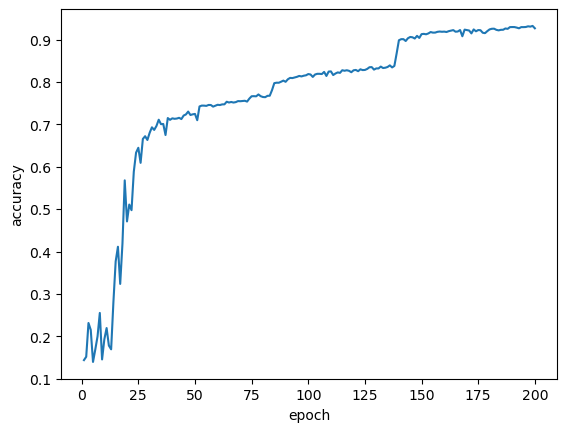

In [149]:
import seaborn as sns
table = pd.DataFrame(table)
sns.lineplot(data=table, x="epoch", y="accuracy")

In [ ]:
rng = np.random.default_rng()      # initiate random
ix_example = np.arange(len(training_inputs))     # array [0,1,...,N]
rng.shuffle(ix_example) 

In [ ]:
len(ix_example)


50000

## *Task 3d. Run the backpropagation algorithm on the entire data-set, how well is it performing?*

This time we will only use 2 epochs to run the entire data-set (end up with 100,000 cases) to see if it still performs correctly and we can validate the model.

In [ ]:
layers = [784,N, 10] #input layer, hidden layer(s), output layer
#initiate weights
num_layers = len(layers)
# running a single epoch consisting of all training examples

# initiating bias and weighs
bias = []
Weight = []
for i, j in zip(layers,layers[1:]):
    bias.append(np.random.randn(j,1)) # a random bias with j rows and 1 col
    Weight.append(np.random.randn(j, i) * np.sqrt(2.0 / i))  # a random Weight matrix with j rows and i cols, scaled to work with relu

cost = []
eta = 0.02 # learn rate
table = [] # for storing
##Start of Epoch loop
NUM_EPOCHS = 2

for epoch in range(NUM_EPOCHS):
    if epoch > 75:
        eta = 0.005
    elif epoch > 50:
        eta = 0.01
        
    
    rng.shuffle(ix_example)
    for i in ix_example:
        x = training_inputs[i]
        y = training_results[i]

    # feedforward
        act = x
        act_list = [x] # store all activations layer-by-layer
        zs = [] # list to store all the z vectors, layer by layer
        for w, b in zip(Weight, bias):
            z = w @ act + b
            zs.append(z)
            act = relu(z )
            act_list.append(act)

    # get the gradients nabla_b and nabla_w for each layer based on the training example
        nabla_b, nabla_w = backpropagation(bias, Weight, num_layers, x, y)
        Weight = [w-eta*nw for w, nw in zip(Weight, nabla_w)]
        bias = [b-eta*nb for b, nb in zip(bias, nabla_b)]
    y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]
    correct_prop_test = evaluate(y_preds, training_results)/len(training_results)
    table.append({"epoch": epoch + 1,"accuracy": correct_prop_test, "eta": eta})
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Accuracy: {correct_prop_test:.4f}")

Epoch 1/2 — Accuracy: 0.9736
Epoch 2/2 — Accuracy: 0.9855


## Entire data-set results

As seen in the previous code block, both of the Epochs score 97% accuracy or higher, therefore validating our model and showing that it works.

In [ ]:
table

[{'epoch': 1, 'accuracy': np.float64(0.97364), 'eta': 0.02},
 {'epoch': 2, 'accuracy': np.float64(0.9855), 'eta': 0.02}]

<Axes: xlabel='epoch', ylabel='accuracy'>

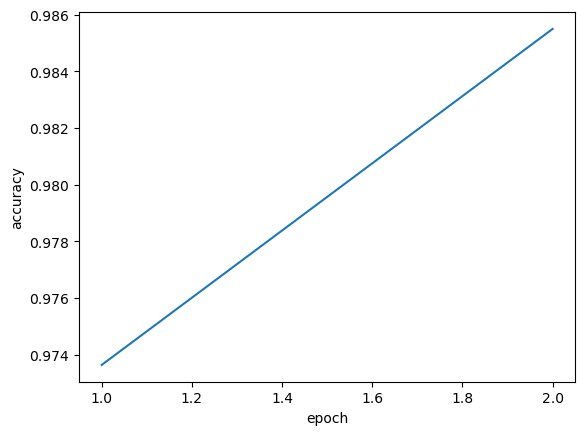

In [ ]:
import seaborn as sns
table = pd.DataFrame(table)
sns.lineplot(data=table, x="epoch", y="accuracy")

In [ ]:
#y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]

In [ ]:
correct_prop= evaluate(y_preds, training_results)/len(training_results)
correct_prop

np.float64(0.9855)